# CNN baseline entrenada desde cero — Galaxy Zoo (elíptica vs. espiral)

Primera CNN real del proyecto (ver `README.md`, sección Arquitectura del modelo): 4 bloques
Conv2d+BatchNorm+ReLU+MaxPool seguidos de un head denso con dropout,
entrenada **desde cero** (sin transfer learning todavía) sobre los mismos
splits que ya usó el notebook de baselines de sklearn
(`notebook/training_baselines.ipynb`).

Objetivo: confirmar que una arquitectura real de deep learning supera al
mejor baseline clásico (HistGradientBoosting, accuracy≈0.870,
ROC-AUC≈0.937 en test) antes de invertir en transfer learning con
ResNet50/ResNet50V2 — siguiendo la receta de Hindarto (2023) (congelar capas
base, fine-tuning progresivo, dropout) descrita en `README.md`.

**Fuente de los datos:** `data/galaxy_zoo_challenge/processed/{train,val,test}.csv`
(mismos splits persistidos, generados por `src/data/make_splits.py`).

**Código reutilizado (no reimplementado acá):**
- `src/data/torch_dataset.py` — `Dataset` con imágenes cacheadas en RAM.
- `src/data/augmentation.py` — transforms de train/eval.
- `src/models/baseline_cnn.py` — arquitectura `BaselineCNN`.
- `src/train.py` — loop de entrenamiento/evaluación por época.
- `src/evaluate.py` — métricas estándar del proyecto (ver `README.md`, sección Métricas de evaluación).

In [1]:
# importaciones de sistema
import sys
import time
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# importaciones de terceros
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import torch
from torch import nn
from torch.utils.data import DataLoader
from sklearn.metrics import RocCurveDisplay

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)


In [2]:
# configuración e imports del proyecto
from src.config import (
    CNN_BATCH_SIZE,
    CNN_DROPOUT,
    CNN_EPOCHS,
    CNN_LEARNING_RATE,
    CNN_NUM_WORKERS,
    MODELS_DIR,
    RANDOM_SEED,
)
from src.data.dataset import load_splits_from_csv
from src.data.augmentation import get_eval_transforms, get_train_transforms
from src.data.torch_dataset import InMemoryGalaxyDataset
from src.models.baseline_cnn import BaselineCNN
from src.train import compute_class_weights, evaluate, fit
from src.evaluate import evaluate_binary_classifier
from src.utils import set_seed

set_seed(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")


Device: cuda
GPU: NVIDIA GeForce RTX 4070 SUPER


## Carga de los splits desde CSV

Mismos `train.csv`/`val.csv`/`test.csv` que usó el notebook de baselines de
sklearn — no se rederiva el split.

In [3]:
train_df, val_df, test_df = load_splits_from_csv()

for name, split in [('train', train_df), ('val', val_df), ('test', test_df)]:
    props = split['label'].value_counts(normalize=True)
    print(f"{name:6s} n={len(split):6d}  elliptical={props.get('elliptical', 0):.1%}  spiral={props.get('spiral', 0):.1%}")


train  n= 16991  elliptical=33.5%  spiral=66.5%
val    n=  3641  elliptical=33.5%  spiral=66.5%
test   n=  3641  elliptical=33.5%  spiral=66.5%


## Datasets y DataLoaders

`InMemoryGalaxyDataset` recorta al centro (`CNN_CROP_SIZE`) y cachea cada
imagen en RAM una sola vez; el augmentation (rotación libre, flips,
traslación, brillo/contraste) se recalcula en cada `__getitem__`, así que
cambia en cada época sin volver a leer disco.

In [4]:
t0 = time.time()
train_ds = InMemoryGalaxyDataset(train_df, transform=get_train_transforms())
val_ds = InMemoryGalaxyDataset(val_df, transform=get_eval_transforms())
print(f"Imágenes cacheadas (train+val): {len(train_ds) + len(val_ds)}")
print(f"Tiempo de carga + recorte: {time.time() - t0:.1f}s")

train_loader = DataLoader(train_ds, batch_size=CNN_BATCH_SIZE, shuffle=True, num_workers=CNN_NUM_WORKERS)
val_loader = DataLoader(val_ds, batch_size=CNN_BATCH_SIZE, shuffle=False, num_workers=CNN_NUM_WORKERS)


Imágenes cacheadas (train+val): 20632
Tiempo de carga + recorte: 20.1s


## Efecto del data augmentation

Visualización obligatoria antes de entrenar (ver `README.md`, sección
Preprocesamiento de imágenes — augmentation agresivo en rotación, ya que las
galaxias no tienen una orientación "correcta" en el cielo, lección
consistente en toda la literatura revisada; pendiente que había quedado
anotado en `notebook/exploration.ipynb`): el recorte centrado cacheado vs.
varias versiones aumentadas de la misma galaxia.

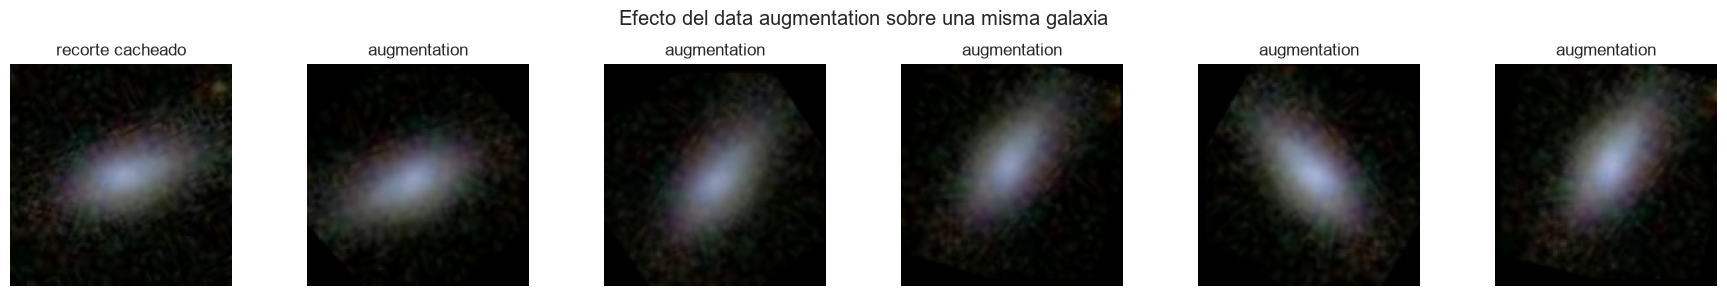

In [5]:
sample_idx = 0
raw_img = Image.fromarray(train_ds.images[sample_idx])
train_transform = get_train_transforms()

fig, axes = plt.subplots(1, 6, figsize=(18, 3))
axes[0].imshow(raw_img)
axes[0].set_title('recorte cacheado')
axes[0].axis('off')
for ax in axes[1:]:
    aug_img = train_transform(raw_img)
    ax.imshow(aug_img.permute(1, 2, 0).numpy())
    ax.set_title('augmentation')
    ax.axis('off')
fig.suptitle('Efecto del data augmentation sobre una misma galaxia')
plt.tight_layout()
plt.show()


## Arquitectura del modelo

4 bloques Conv2d+BatchNorm+ReLU+MaxPool (3→32→64→128→256 canales) +
`AdaptiveAvgPool2d` + head denso con dropout (`src/models/baseline_cnn.py`).

In [6]:
model = BaselineCNN(dropout=CNN_DROPOUT).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"\nParámetros entrenables: {n_params:,}")


BaselineCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (3): Sequential(
      

## Entrenamiento

`class_weight` balanceado en la pérdida (`CrossEntropyLoss`), como en los
baselines de sklearn (ver `README.md`, sección Manejo de desbalance de
clases). Se conservan los pesos de la época con mejor ROC-AUC en validación.

In [7]:
class_weights = compute_class_weights(train_df, device)
print(f"Pesos de clase [elíptica, espiral]: {class_weights.cpu().numpy()}")

t0 = time.time()
history = fit(model, train_loader, val_loader, class_weights, device, epochs=CNN_EPOCHS, lr=CNN_LEARNING_RATE)
print(f"\nTiempo total de entrenamiento: {time.time() - t0:.1f}s")


Pesos de clase [elíptica, espiral]: [1.4925333 0.7518807]


[01/8] train_loss=0.2787  val_loss=0.2364  val_acc=0.8989  val_auc=0.9703  (18.4s)


[02/8] train_loss=0.1836  val_loss=0.2803  val_acc=0.9129  val_auc=0.9774  (18.2s)


[03/8] train_loss=0.1585  val_loss=0.1084  val_acc=0.9615  val_auc=0.9927  (16.4s)


[04/8] train_loss=0.1374  val_loss=0.4639  val_acc=0.8726  val_auc=0.9885  (16.3s)


[05/8] train_loss=0.1285  val_loss=0.1208  val_acc=0.9687  val_auc=0.9951  (16.6s)


[06/8] train_loss=0.1217  val_loss=0.1002  val_acc=0.9632  val_auc=0.9944  (16.2s)


[07/8] train_loss=0.1097  val_loss=0.0966  val_acc=0.9717  val_auc=0.9938  (16.4s)


[08/8] train_loss=0.1077  val_loss=0.0891  val_acc=0.9676  val_auc=0.9950  (16.5s)

Tiempo total de entrenamiento: 135.1s


## Curvas de entrenamiento

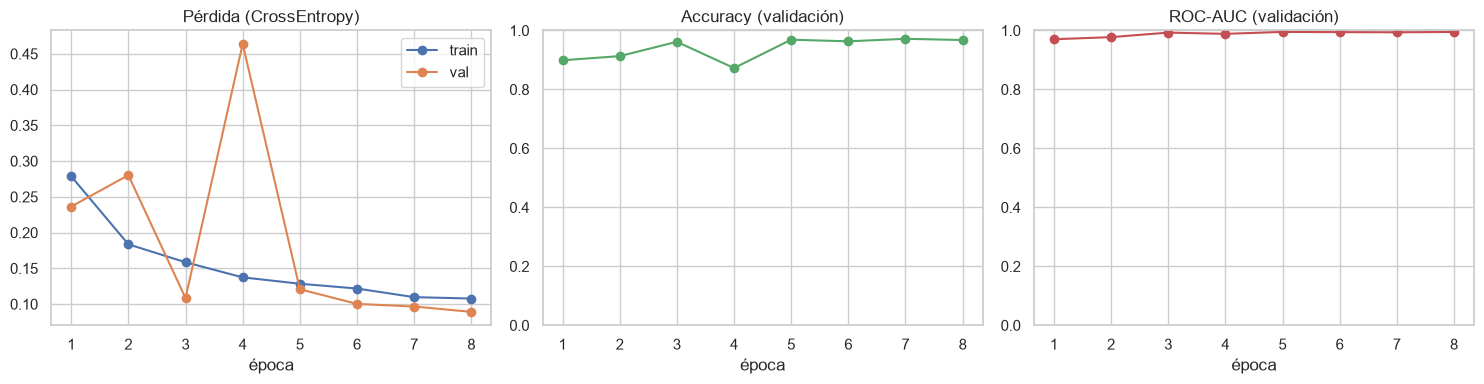

In [8]:
epochs_range = range(1, len(history['train_loss']) + 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(epochs_range, history['train_loss'], marker='o', label='train')
axes[0].plot(epochs_range, history['val_loss'], marker='o', label='val')
axes[0].set_title('Pérdida (CrossEntropy)')
axes[0].set_xlabel('época')
axes[0].legend()

axes[1].plot(epochs_range, history['val_accuracy'], marker='o', color='#55A868')
axes[1].set_title('Accuracy (validación)')
axes[1].set_xlabel('época')
axes[1].set_ylim(0, 1)

axes[2].plot(epochs_range, history['val_roc_auc'], marker='o', color='#C44E52')
axes[2].set_title('ROC-AUC (validación)')
axes[2].set_xlabel('época')
axes[2].set_ylim(0, 1)

plt.tight_layout()
plt.show()


In [9]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
torch.save(model.state_dict(), MODELS_DIR / 'best_cnn_baseline.pt')
print(f"Modelo (mejor época por ROC-AUC en validación) guardado en {MODELS_DIR / 'best_cnn_baseline.pt'}")


Modelo (mejor época por ROC-AUC en validación) guardado en C:\Users\Alexander CC\Documents\Projects\python\clasificacion-galaxias\models\best_cnn_baseline.pt


## Evaluación final sobre test

El split de `test` no participó ni en el entrenamiento ni en la selección de
la mejor época: se evalúa una sola vez, con los pesos ya cargados de la
mejor época, para reportar una estimación no sesgada del desempeño.

In [10]:
test_ds = InMemoryGalaxyDataset(test_df, transform=get_eval_transforms())
test_loader = DataLoader(test_ds, batch_size=CNN_BATCH_SIZE, shuffle=False, num_workers=CNN_NUM_WORKERS)

criterion = nn.CrossEntropyLoss(weight=class_weights)
test_loss, y_test_true, y_test_pred, y_test_proba = evaluate(model, test_loader, criterion, device)
test_metrics = evaluate_binary_classifier(y_test_true, y_test_pred, y_test_proba)

print(f"Test -- loss: {test_loss:.4f}  accuracy: {test_metrics['accuracy']:.4f}  ROC-AUC: {test_metrics['roc_auc']:.4f}")
print("\nMatriz de confusión (test):")
print(test_metrics['confusion_matrix'])
print("\nReporte por clase:")
pd.DataFrame(test_metrics['report']).T


Test -- loss: 0.1150  accuracy: 0.9679  ROC-AUC: 0.9957

Matriz de confusión (test):
[[1117  103]
 [  14 2407]]

Reporte por clase:


,precision,recall,f1-score,support
0,0.987622,0.915574,0.950234,1220.000000
1,0.958964,0.994217,0.976273,2421.000000
accuracy,0.967866,0.967866,0.967866,0.967866
macro avg,0.973293,0.954896,0.963253,3641.000000
weighted avg,0.968566,0.967866,0.967548,3641.000000


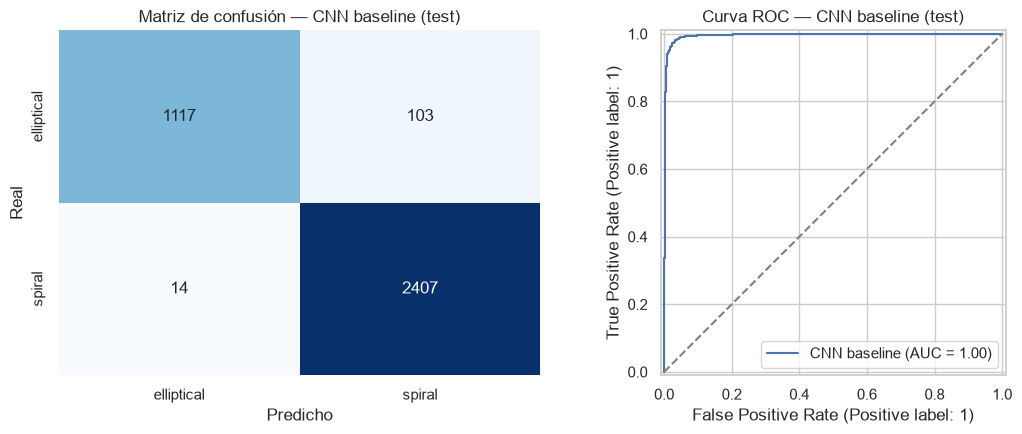

In [11]:
labels_names = ['elliptical', 'spiral']
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.heatmap(test_metrics['confusion_matrix'], annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=labels_names, yticklabels=labels_names, ax=axes[0])
axes[0].set_title('Matriz de confusión — CNN baseline (test)')
axes[0].set_xlabel('Predicho')
axes[0].set_ylabel('Real')

RocCurveDisplay.from_predictions(y_test_true, y_test_proba, name='CNN baseline', ax=axes[1])
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[1].set_title('Curva ROC — CNN baseline (test)')

plt.tight_layout()
plt.show()


## Comparación con el mejor baseline de sklearn

Referencia: `HistGradientBoosting` (`notebook/training_baselines.ipynb`),
evaluado también una sola vez sobre el mismo split de test.

In [12]:
print("sklearn (HistGradientBoosting, test): accuracy=0.870  roc_auc=0.937")
print(f"CNN baseline            (test): accuracy={test_metrics['accuracy']:.3f}  roc_auc={test_metrics['roc_auc']:.3f}")


sklearn (HistGradientBoosting, test): accuracy=0.870  roc_auc=0.937
CNN baseline            (test): accuracy=0.968  roc_auc=0.996


## Conclusiones

- CNN de 4 bloques conv entrenada desde cero, con augmentation agresivo en
  rotación/flip/traslación/brillo (obligatorio según `README.md`, sección
  Preprocesamiento de imágenes — ver Dieleman, Willett & Dambre 2015)
  y `class_weight` balanceado en la pérdida (sección Manejo de desbalance de clases).
- Entrenamiento y evaluación corridos sobre los splits **completos**
  persistidos en `data/galaxy_zoo_challenge/processed/`, igual que el notebook de
  baselines de sklearn — comparación directa, mismo test set.
- Ver la celda de comparación arriba para accuracy/ROC-AUC de la CNN vs. el
  mejor baseline clásico (HistGradientBoosting).
- Referencia de literatura (ver `README.md`, sección Métricas de evaluación):
  ~94.5–99% OA en binario es el rango reportado por Dieleman et al. (2015) y
  Barchi et al. (2020) para arquitecturas CNN más maduras (con invarianza
  rotacional explícita o transfer learning). Esta CNN baseline, entrenada
  desde cero y con pocas épocas, es un primer punto de referencia — no el
  resultado final de la fase 1.
- Próximo paso natural: transfer learning con ResNet50/ResNet50V2
  preentrenada en ImageNet (ver `README.md`, sección Arquitectura del
  modelo), reutilizando los mismos splits y las mismas funciones de
  `src/train.py`/`src/evaluate.py`.

<!-- Autor: Alexander Carreño Correa (alexandercorreacorrea1997@gmail.com) -->